# Jobsheet 02 – Klasifikasi Gambar


In [3]:
# ===== Setup umum =====
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist, cifar10
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

# Menampung hasil tiap praktikum untuk tabel "Hasil Praktikum"
hasil = {}


def plot_history(history, judul):
    """Plot akurasi & loss (training vs validation) dari objek history Keras."""
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{judul} Accuracy')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{judul} Loss')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
    plt.tight_layout()
    plt.show()


## Praktikum D1 – Memulai Klasifikasi Gambar dengan Dataset Sederhana (MNIST)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28) | y_train: (60000,)
x_test : (10000, 28, 28) | y_test : (10000,)


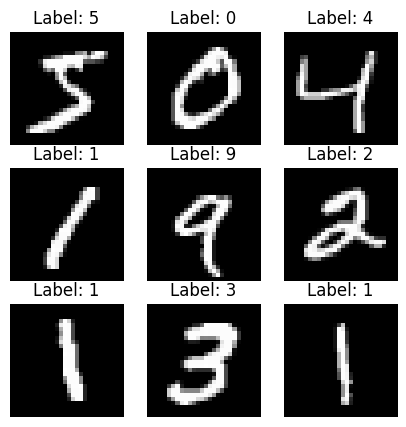

In [4]:
# Load data MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_test :", x_test.shape, "| y_test :", y_test.shape)

# Tampilkan contoh (9 gambar)
plt.figure(figsize=(5, 5))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

**Task D1:** ganti `range(9)` menjadi `range(25)`.

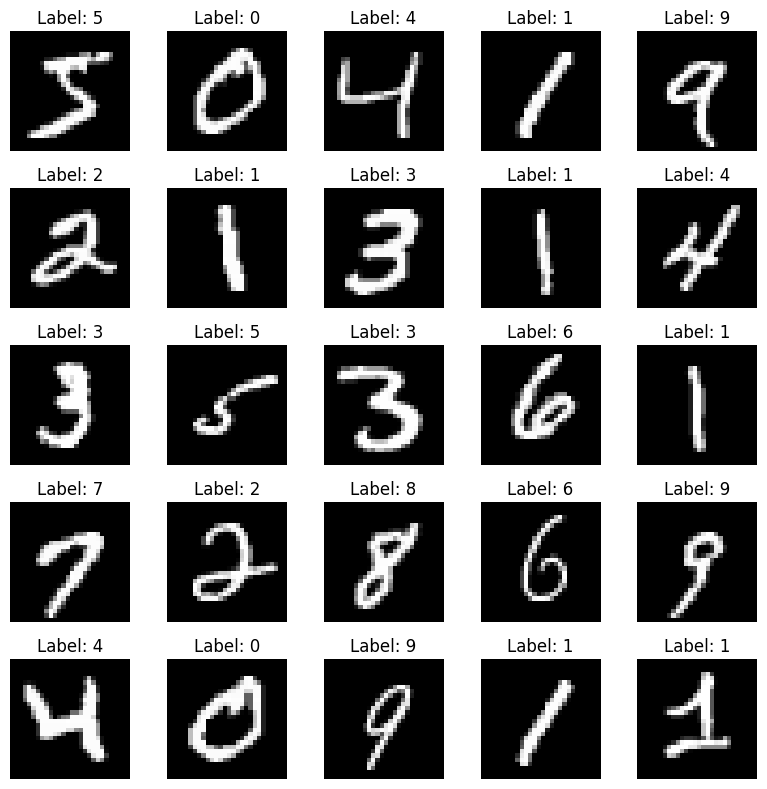

In [5]:
# Tugas kecil D1: tampilkan 25 contoh (grid 5x5)
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

hasil['D1'] = "Dataset MNIST dimuat: 60.000 data latih & 10.000 data uji, ukuran 28x28 grayscale, 10 kelas (0-9)."


## Praktikum D2 – Klasifikasi dengan Machine Learning Tradisional (SVM)

In [6]:
# Flatten 28x28 -> 784 dan normalisasi
x_train_flat = x_train.reshape(len(x_train), -1) / 255.0
x_test_flat = x_test.reshape(len(x_test), -1) / 255.0

# SVM kernel linear (subset 5000 data latih karena SVM berat)
clf = svm.SVC(kernel='linear', gamma='scale')
clf.fit(x_train_flat[:5000], y_train[:5000])

y_pred = clf.predict(x_test_flat)
acc_linear = accuracy_score(y_test, y_pred)
print("Akurasi (linear):", acc_linear)
hasil['D2 SVM linear'] = acc_linear

Akurasi (linear): 0.9101


**Task D2:** ubah kernel dari `linear` menjadi `rbf`.

In [7]:
# Tugas kecil D2: kernel RBF
clf_rbf = svm.SVC(kernel='rbf', gamma='scale')
clf_rbf.fit(x_train_flat[:5000], y_train[:5000])

y_pred_rbf = clf_rbf.predict(x_test_flat)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print("Akurasi (rbf)   :", acc_rbf)
print("Akurasi (linear):", acc_linear)
print("Selisih         :", acc_rbf - acc_linear)
hasil['D2 SVM rbf'] = acc_rbf

Akurasi (rbf)   : 0.9513
Akurasi (linear): 0.9101
Selisih         : 0.041200000000000014



## Praktikum D3 – Membangun CNN Sederhana (MNIST)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9457 - loss: 0.1810 - val_accuracy: 0.9800 - val_loss: 0.0716
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9811 - loss: 0.0626 - val_accuracy: 0.9842 - val_loss: 0.0573
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9883 - loss: 0.0403 - val_accuracy: 0.9812 - val_loss: 0.0664
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9923 - loss: 0.0271 - val_accuracy: 0.9817 - val_loss: 0.0684
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9949 - loss: 0.0178 - val_accuracy: 0.9818 - val_loss: 0.0752


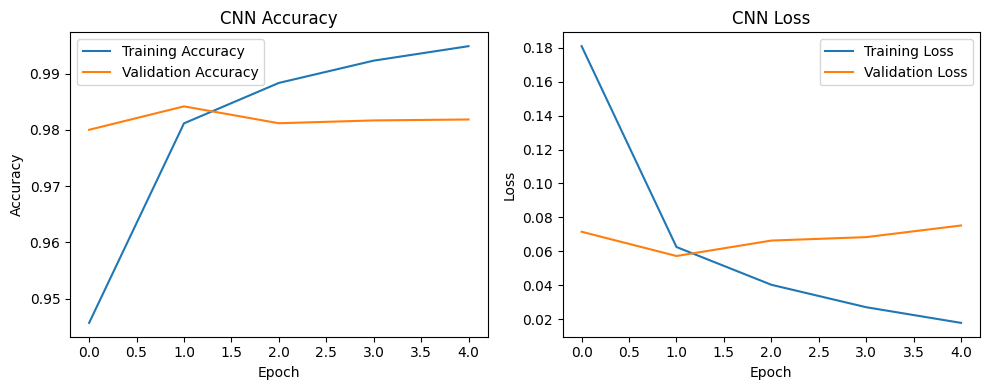

Akurasi test CNN (D3): 0.9768


In [8]:
# Bentuk data: [samples, height, width, channels]
x_train_cnn = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test_cnn = x_test.reshape(-1, 28, 28, 1) / 255.0

model_d3 = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_d3.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])
model_d3.summary()

history_d3 = model_d3.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)

# ===== Plot history =====
plot_history(history_d3, 'CNN')

loss_d3, acc_d3 = model_d3.evaluate(x_test_cnn, y_test, verbose=0)
print(f"Akurasi test CNN (D3): {acc_d3:.4f}")
hasil['D3 CNN 1 Conv'] = acc_d3

**Task D3:** tambahkan satu lapisan `Conv2D` lagi sebelum `Flatten`.

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9621 - loss: 0.1236 - val_accuracy: 0.9828 - val_loss: 0.0580
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9865 - loss: 0.0414 - val_accuracy: 0.9873 - val_loss: 0.0493
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9918 - loss: 0.0260 - val_accuracy: 0.9875 - val_loss: 0.0499
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9939 - loss: 0.0181 - val_accuracy: 0.9880 - val_loss: 0.0529
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9958 - loss: 0.0131 - val_accuracy: 0.9912 - val_loss: 0.0412


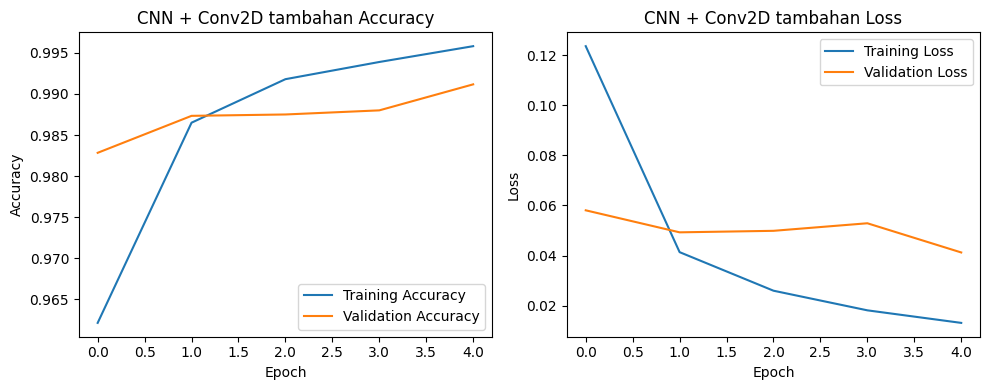

Akurasi test CNN 1 Conv : 0.9768
Akurasi test CNN 2 Conv : 0.9883


In [9]:
# Tugas kecil D3: CNN dengan 2 lapisan Conv2D
model_d3_deep = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),   # lapisan tambahan
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_d3_deep.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy',
                      metrics=['accuracy'])

history_d3_deep = model_d3_deep.fit(x_train_cnn, y_train, epochs=5, validation_split=0.1)
plot_history(history_d3_deep, 'CNN + Conv2D tambahan')

loss_d3d, acc_d3d = model_d3_deep.evaluate(x_test_cnn, y_test, verbose=0)
print(f"Akurasi test CNN 1 Conv : {acc_d3:.4f}")
print(f"Akurasi test CNN 2 Conv : {acc_d3d:.4f}")
hasil['D3 CNN 2 Conv'] = acc_d3d


## Praktikum D4 – Dataset Lebih Kompleks (CIFAR-10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4914s 29us/step
x_train_c: (50000, 32, 32, 3) | x_test_c: (10000, 32, 32, 3)
Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.4658 - loss: 1.4861 - val_accuracy: 0.5692 - val_loss: 1.2283
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5990 - loss: 1.1433 - val_accuracy: 0.6166 - val_loss: 1.0797
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.6466 - loss: 1.0186 - val_accuracy: 0.6458 - val_loss: 1.0119
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6789 - loss: 0.9307 - val_accuracy: 0.6660 - val_loss: 0.9738
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7018 - loss: 0.8605 - val_accuracy: 0.6704 - val_loss: 0.9678
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7225 - loss: 0.8031 - val_accuracy: 0.6832 - val_loss: 0.9496
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7384 - loss: 0.7544 - val_accurac

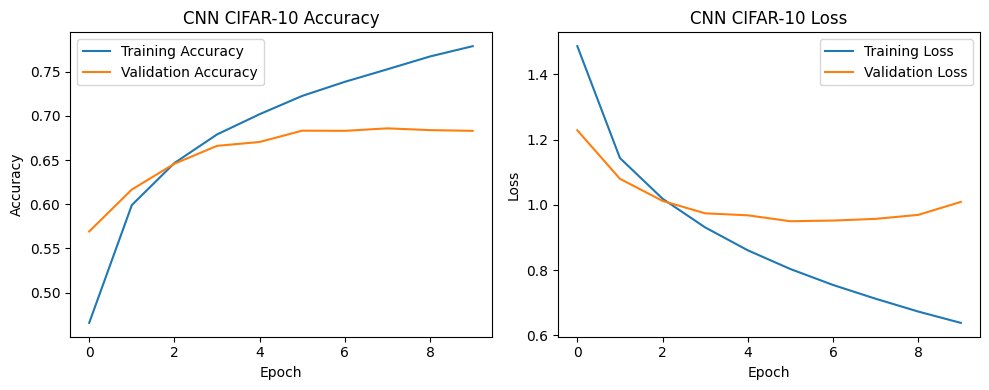

Akurasi test CIFAR-10 (tanpa dropout): 0.6734
Perbandingan: MNIST CNN = 0.9768 vs CIFAR-10 CNN = 0.6734


In [10]:
# Load CIFAR-10 (variabel dipisah agar data MNIST tidak tertimpa)
(x_train_c, y_train_c), (x_test_c, y_test_c) = cifar10.load_data()
x_train_c, x_test_c = x_train_c / 255.0, x_test_c / 255.0

nama_kelas = ['airplane', 'automobile', 'bird', 'cat', 'deer',
              'dog', 'frog', 'horse', 'ship', 'truck']
print("x_train_c:", x_train_c.shape, "| x_test_c:", x_test_c.shape)

model_d4 = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_d4.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

history_d4 = model_d4.fit(x_train_c, y_train_c, epochs=10, validation_split=0.1)

# ===== Plot history =====
plot_history(history_d4, 'CNN CIFAR-10')

loss_d4, acc_d4 = model_d4.evaluate(x_test_c, y_test_c, verbose=0)
print(f"Akurasi test CIFAR-10 (tanpa dropout): {acc_d4:.4f}")
print(f"Perbandingan: MNIST CNN = {acc_d3:.4f} vs CIFAR-10 CNN = {acc_d4:.4f}")
hasil['D4 CNN CIFAR-10'] = acc_d4

**Task D4:** tambahkan `Dropout(0.5)` sebelum lapisan Dense terakhir.

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.3567 - loss: 1.7430 - val_accuracy: 0.5020 - val_loss: 1.3944
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.4860 - loss: 1.4286 - val_accuracy: 0.5704 - val_loss: 1.2019
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5469 - loss: 1.2808 - val_accuracy: 0.6134 - val_loss: 1.1141
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5740 - loss: 1.1966 - val_accuracy: 0.6372 - val_loss: 1.0334
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5966 - loss: 1.1330 - val_accuracy: 0.6510 - val_loss: 1.0137
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6178 - loss: 1.0784 - val_accuracy: 0.6708 - val_loss: 0.9552
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6318 - loss: 1.0396 - val_accuracy: 0.6674 - val_loss: 0.9524
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6444 - loss: 1.0014 -

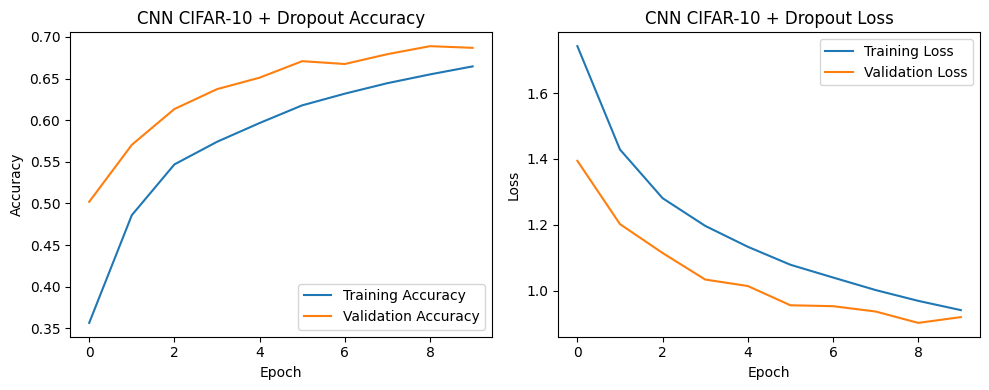

Tanpa Dropout : test acc = 0.6734 | gap train-val = 0.0958
Dengan Dropout: test acc = 0.6787 | gap train-val = -0.0223


In [11]:
# Tugas kecil D4: tambahkan Dropout(0.5)
model_d4_do = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),                       # sebelum Dense terakhir
    layers.Dense(10, activation='softmax')
])

model_d4_do.compile(optimizer='adam',
                    loss='sparse_categorical_crossentropy',
                    metrics=['accuracy'])

history_d4_do = model_d4_do.fit(x_train_c, y_train_c, epochs=10, validation_split=0.1)
plot_history(history_d4_do, 'CNN CIFAR-10 + Dropout')

loss_d4d, acc_d4d = model_d4_do.evaluate(x_test_c, y_test_c, verbose=0)


def gap(h):
    # selisih training - validation accuracy di epoch terakhir (indikator overfitting)
    return h.history['accuracy'][-1] - h.history['val_accuracy'][-1]


print(f"Tanpa Dropout : test acc = {acc_d4:.4f} | gap train-val = {gap(history_d4):.4f}")
print(f"Dengan Dropout: test acc = {acc_d4d:.4f} | gap train-val = {gap(history_d4_do):.4f}")
hasil['D4 CNN CIFAR-10 + Dropout'] = acc_d4d


## Praktikum D5 – Transfer Learning (VGG16)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.5156 - loss: 1.3857 - val_accuracy: 0.5654 - val_loss: 1.2480
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.5837 - loss: 1.1970 - val_accuracy: 0.5782 - val_loss: 1.2035
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6046 - loss: 1.1379 - val_accuracy: 0.5914 - val_loss: 1.1785
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6197 - loss: 1.0971 - val_accuracy: 0.5984 - val_loss: 1.1619
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6298 - loss: 1.0637 - val_accuracy: 0.6040 - val_loss: 1.1519


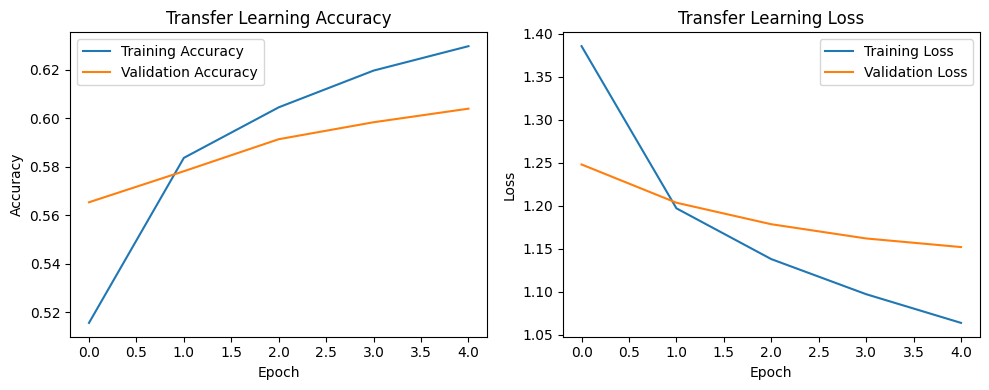

Akurasi test (feature extraction VGG16): 0.5903


In [12]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
base_model.trainable = False          # bekukan seluruh lapisan konvolusi

model_d5 = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_d5.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

history_d5 = model_d5.fit(x_train_c, y_train_c, epochs=5, validation_split=0.1)

# ===== Plot history =====
plot_history(history_d5, 'Transfer Learning')

loss_d5, acc_d5 = model_d5.evaluate(x_test_c, y_test_c, verbose=0)
print(f"Akurasi test (feature extraction VGG16): {acc_d5:.4f}")
hasil['D5 VGG16 feature extraction'] = acc_d5

**Task D5:** aktifkan 1–2 lapisan terakhir dari `base_model` (fine-tuning).

Lapisan yang dilatih: ['block5_conv2', 'block5_conv3']
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.6648 - loss: 0.9617 - val_accuracy: 0.6524 - val_loss: 1.0136
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.7086 - loss: 0.8356 - val_accuracy: 0.6670 - val_loss: 0.9764
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.7399 - loss: 0.7493 - val_accuracy: 0.6746 - val_loss: 0.9573
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.7668 - loss: 0.6792 - val_accuracy: 0.6782 - val_loss: 0.9469
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - accuracy: 0.7917 - loss: 0.6182 - val_accuracy: 0.6826 - val_loss: 0.9397


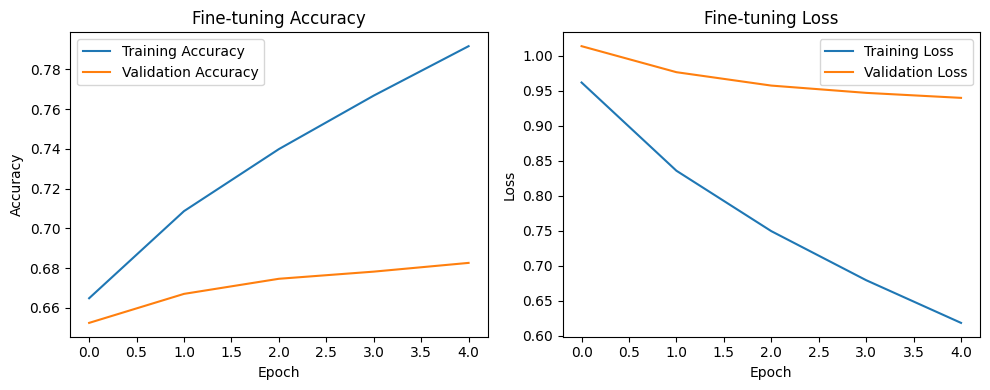

Feature extraction: 0.5903
Fine-tuning       : 0.6754


In [13]:
# Tugas kecil D5: fine-tuning -> buka 2 lapisan konvolusi terakhir (block5_conv2, block5_conv3)
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name in ('block5_conv2', 'block5_conv3')

print("Lapisan yang dilatih:", [l.name for l in base_model.layers if l.trainable])

# WAJIB compile ulang setelah mengubah trainable; learning rate kecil agar bobot pra-latih tidak rusak
model_d5.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

history_d5_ft = model_d5.fit(x_train_c, y_train_c, epochs=5, validation_split=0.1)
plot_history(history_d5_ft, 'Fine-tuning')

loss_d5f, acc_d5f = model_d5.evaluate(x_test_c, y_test_c, verbose=0)
print(f"Feature extraction: {acc_d5:.4f}")
print(f"Fine-tuning       : {acc_d5f:.4f}")
hasil['D5 VGG16 fine-tuning'] = acc_d5f


## Praktikum D6 – Evaluasi: Confusion Matrix, Precision, Recall, F1-score
(Menggunakan model D5 setelah fine-tuning pada data uji CIFAR-10)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step
              precision    recall  f1-score   support

    airplane       0.79      0.67      0.73      1000
  automobile       0.83      0.68      0.75      1000
        bird       0.67      0.55      0.60      1000
         cat       0.52      0.47      0.49      1000
        deer       0.64      0.61      0.63      1000
         dog       0.55      0.62      0.58      1000
        frog       0.75      0.69      0.72      1000
       horse       0.70      0.77      0.74      1000
        ship       0.70      0.88      0.78      1000
       truck       0.65      0.81      0.72      1000

    accuracy                           0.68     10000
   macro avg       0.68      0.68      0.67     10000
weighted avg       0.68      0.68      0.67     10000



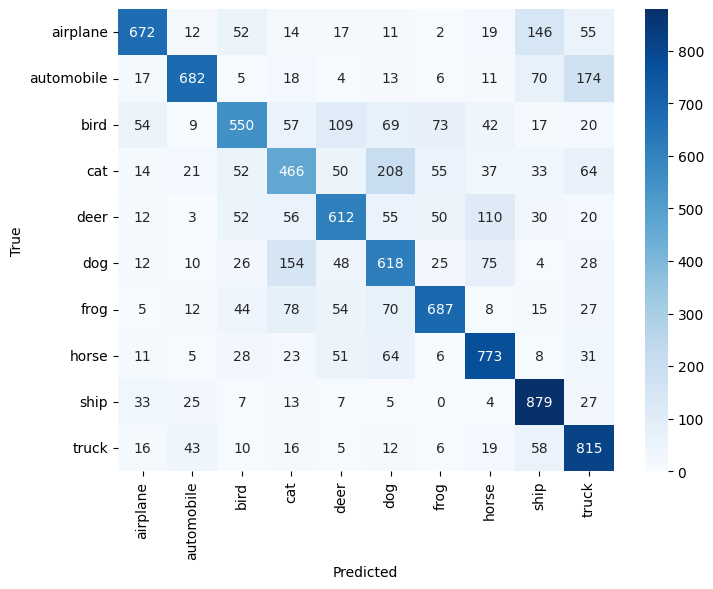

In [14]:
y_true = y_test_c.ravel()
y_pred = model_d5.predict(x_test_c).argmax(axis=1)

print(classification_report(y_true, y_pred, target_names=nama_kelas))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nama_kelas, yticklabels=nama_kelas)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

hasil['D6 akurasi evaluasi'] = accuracy_score(y_true, y_pred)

**Task D6:** identifikasi kelas yang paling sering salah diklasifikasikan.

In [15]:
# Pasangan (kelas asli -> prediksi salah) yang paling sering terjadi
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
i, j = np.unravel_index(cm_off.argmax(), cm_off.shape)
print(f"Kesalahan terbanyak: '{nama_kelas[i]}' diprediksi sebagai '{nama_kelas[j]}' ({cm_off[i, j]} kali)")

# Kelas dengan recall terendah
recall_per_kelas = cm.diagonal() / cm.sum(axis=1)
terburuk = recall_per_kelas.argmin()
print(f"Recall terendah: '{nama_kelas[terburuk]}' = {recall_per_kelas[terburuk]:.3f}")

# 5 pasangan kesalahan teratas
top = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
print("\nTop 5 pasangan salah klasifikasi:")
for a, b in top:
    print(f"- {nama_kelas[a]} -> {nama_kelas[b]}: {cm_off[a, b]}")

Kesalahan terbanyak: 'cat' diprediksi sebagai 'dog' (208 kali)
Recall terendah: 'cat' = 0.466

Top 5 pasangan salah klasifikasi:
- cat -> dog: 208
- automobile -> truck: 174
- dog -> cat: 154
- airplane -> ship: 146
- deer -> horse: 110


In [16]:
# ===== 1) Upload file foto tulisan angka =====
from google.colab import files
uploaded = files.upload()   # pilih 1 atau lebih file gambar (jpg/png)

Saving WhatsApp Image 2026-10-16 at 20.32.34.jpeg to WhatsApp Image 2026-10-16 at 20.32.34.jpeg


In [17]:
# ===== 2) Utilitas preprocess agar mirip MNIST (28x28, putih di atas hitam) =====
from PIL import Image, ImageOps


def preprocess_to_mnist_28x28(img_pil):
    """
    Langkah:
    - Konversi ke grayscale + auto-contrast
    - Invert bila latar terang (digit putih, latar gelap seperti MNIST)
    - Crop ke bounding box digit
    - Resize mempertahankan rasio ke maks 20x20, lalu pad ke 28x28
    - Normalisasi ke [0,1] dan tambah axis channel
    Return: (gambar PIL 28x28, array float32 shape (28,28,1))
    """
    # Grayscale + autocontrast
    img = img_pil.convert('L')
    img = ImageOps.autocontrast(img)
    arr = np.array(img).astype(np.uint8)

    # Kertas putih -> invert agar digit putih di atas latar gelap
    if arr.mean() > 127:
        img = ImageOps.invert(img)
        arr = np.array(img)

    # Ambang adaptif sederhana untuk mencari bounding box digit
    thr = arr.mean() + 0.5 * arr.std()
    mask = arr > thr
    if mask.any():
        ys, xs = np.where(mask)
        img = img.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))

    # Resize ke sisi terpanjang = 20 px (rasio dipertahankan)
    w, h = img.size
    scale = 20.0 / max(w, h)
    new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    img = img.resize((new_w, new_h), Image.Resampling.LANCZOS)

    # Pad ke 28x28 dan letakkan di tengah
    canvas = Image.new('L', (28, 28), color=0)
    canvas.paste(img, ((28 - new_w) // 2, (28 - new_h) // 2))

    # Normalisasi ke [0,1] + channel dim
    arr = np.array(canvas).astype('float32') / 255.0
    arr = arr[..., None]       # (28,28,1)
    return canvas, arr

### (Pilihan A) Prediksi dengan CNN dari D3

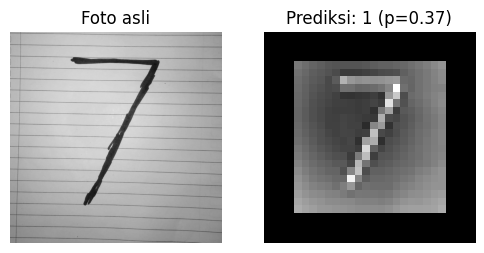

Rekap Prediksi (CNN):
- WhatsApp Image 2026-10-16 at 20.32.34.jpeg -> 1 (p=0.367)


In [18]:
results_cnn = []

for fname in uploaded.keys():
    img_pil = Image.open(fname)
    disp, x = preprocess_to_mnist_28x28(img_pil)   # disp: PIL 28x28, x: (28,28,1)
    x_batch = np.expand_dims(x, axis=0)            # (1,28,28,1)

    probs = model_d3.predict(x_batch, verbose=0)[0]  # shape (10,)
    pred = int(np.argmax(probs))
    conf = float(np.max(probs))
    results_cnn.append((fname, pred, conf))

    # Tampilkan foto asli + hasil preprocess
    plt.figure(figsize=(6, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(img_pil.convert('L'), cmap='gray'); plt.title('Foto asli'); plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(disp, cmap='gray'); plt.title(f"Prediksi: {pred} (p={conf:.2f})"); plt.axis('off')
    plt.show()

print("Rekap Prediksi (CNN):")
for r in results_cnn:
    print(f"- {r[0]} -> {r[1]} (p={r[2]:.3f})")

### (Pilihan B) Prediksi dengan SVM dari D2

In [19]:
results_svm = []

for fname in uploaded.keys():
    img_pil = Image.open(fname)
    _, x = preprocess_to_mnist_28x28(img_pil)   # x: (28,28,1) float [0,1]
    x_flat = x.reshape(1, -1)                   # (1,784)

    pred = int(clf_rbf.predict(x_flat)[0])      # SVM RBF (lebih akurat dari linear)
    pred_lin = int(clf.predict(x_flat)[0])      # SVM linear sebagai pembanding

    # SVC default tidak punya predict_proba (perlu SVC(probability=True) saat pelatihan)
    conf = None
    if hasattr(clf_rbf, "predict_proba"):
        try:
            conf = float(np.max(clf_rbf.predict_proba(x_flat)))
        except Exception:
            pass

    results_svm.append((fname, pred, conf))
    print(f"{fname} -> SVM rbf: {pred}, SVM linear: {pred_lin}" + (f" (p≈{conf:.2f})" if conf is not None else ""))

WhatsApp Image 2026-10-16 at 20.32.34.jpeg -> SVM rbf: 2, SVM linear: 2


### Yang dilaporkan di laporan
1. 1–2 gambar hasil (display 28×28) + label prediksi & probabilitas (dari sel Pilihan A).
2. Rekap file → prediksi SVM (Pilihan B).
3. Refleksi 2–3 kalimat: apakah prediksi benar? Jika salah, kemungkinan penyebab (pencahayaan, ketebalan tulisan, preprocessing, posisi digit). Bandingkan performa SVM vs CNN pada tulisan tangan Anda.


## Ringkasan Hasil (untuk tabel "Hasil Praktikum")

In [20]:
print("=" * 60)
print("RINGKASAN HASIL PRAKTIKUM")
print("=" * 60)
for k, v in hasil.items():
    if isinstance(v, (float, np.floating)):
        print(f"{k:32s}: akurasi = {v:.4f} ({v*100:.2f}%)")
    else:
        print(f"{k:32s}: {v}")

RINGKASAN HASIL PRAKTIKUM
D1                              : Dataset MNIST dimuat: 60.000 data latih & 10.000 data uji, ukuran 28x28 grayscale, 10 kelas (0-9).
D2 SVM linear                   : akurasi = 0.9101 (91.01%)
D2 SVM rbf                      : akurasi = 0.9513 (95.13%)
D3 CNN 1 Conv                   : akurasi = 0.9768 (97.68%)
D3 CNN 2 Conv                   : akurasi = 0.9883 (98.83%)
D4 CNN CIFAR-10                 : akurasi = 0.6734 (67.34%)
D4 CNN CIFAR-10 + Dropout       : akurasi = 0.6787 (67.87%)
D5 VGG16 feature extraction     : akurasi = 0.5903 (59.03%)
D5 VGG16 fine-tuning            : akurasi = 0.6754 (67.54%)
D6 akurasi evaluasi             : akurasi = 0.6754 (67.54%)
